## Compare complexity measures

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
real = pd.read_csv('../results/real.csv')
stage1 = pd.read_csv('../results/kumo_stage1.csv')
stage2 = pd.read_csv('../results/kumo_stage2.csv')
stage3 = pd.read_csv('../results/kumo_stage3.csv')

In [8]:
real.shape, stage1.shape, stage2.shape, stage3.shape

((216, 21), (53396, 21), (40493, 21), (2821, 21))

In [9]:
real.head()

,id,n_classes,n_rows,n_cols,c1,c2,f1.nanmean,f1v.nanmean,f2.nanmean,f3.nanmean,...,l1.nanmean,l2.nanmean,l3.nanmean,n1,n2.nanmean,n3.nanmean,t1,t2,t3,t4
0,credit-g.csv,2,1000,20,0.881291,0.275862,0.989011,0.349465,0.661921,0.986000,...,0.137186,0.214000,0.194000,0.432000,0.443736,0.288000,0.702000,0.049000,0.001000,0.020408
1,diabetes.csv,2,768,8,0.933134,0.167247,0.941687,0.343559,0.251596,0.993490,...,0.147428,0.226562,0.194010,0.436198,0.454192,0.302083,0.687500,0.010417,0.002604,0.250000
2,Fitness_Club.csv,2,1500,6,0.884526,0.269540,0.979568,0.389697,0.135069,0.952667,...,0.136422,0.222667,0.218000,0.432000,0.396749,0.290667,0.442000,0.010667,0.002000,0.187500
3,maternal_health_risk.csv,3,1014,6,0.988027,0.019554,0.857807,0.341238,0.173997,0.869433,...,0.138938,0.201099,0.185338,0.301775,0.075208,0.160750,0.184418,0.005917,0.003945,0.666667
4,qsar-biodeg.csv,2,1054,41,0.921735,0.192533,0.952321,0.185624,0.000000,0.920304,...,0.087943,0.108159,0.126186,0.273245,0.351579,0.170778,0.376660,0.038899,0.006641,0.170732


In [10]:
def barplot(df, base):
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.8))
    for ax, col in zip(axes, df.columns[1:4]):
        if col not in df:
            ax.set_visible(False); continue
        v = df[col]
        ax.hist(v, bins=30, linewidth=1)
        ax.set_title(col)
        ax.grid(axis="x", visible=False)
    fig.suptitle(f'Características dos datasets {base}', x=0.01, ha="left")
    fig.tight_layout()
    plt.show()

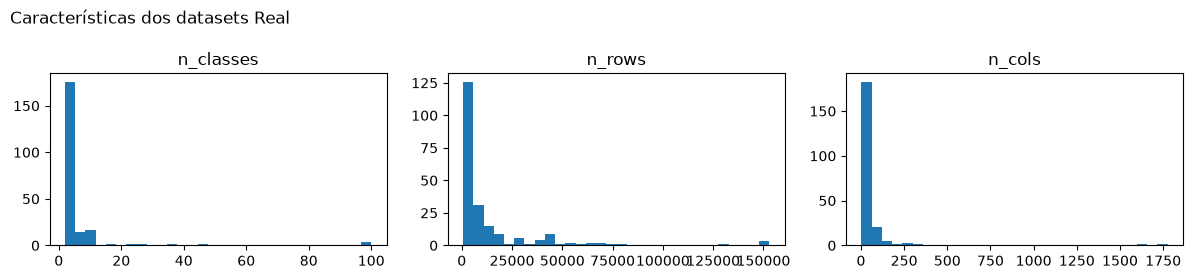

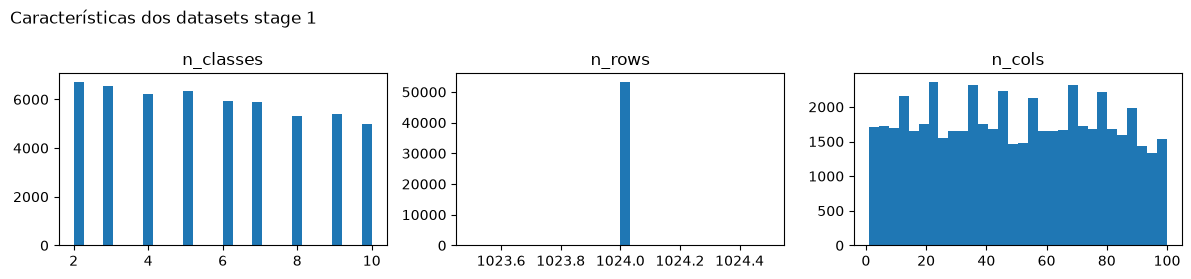

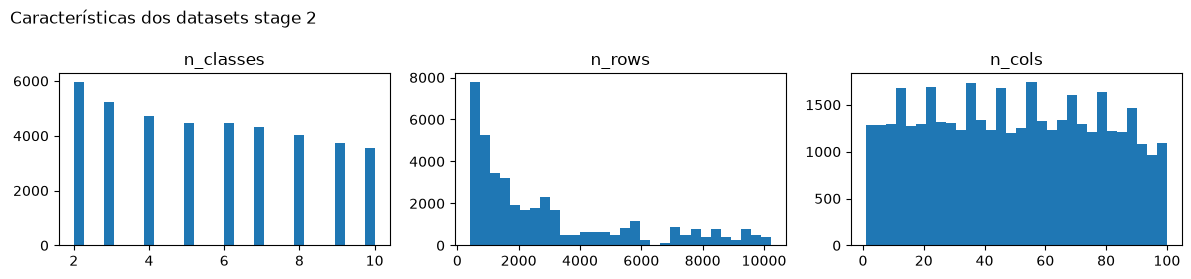

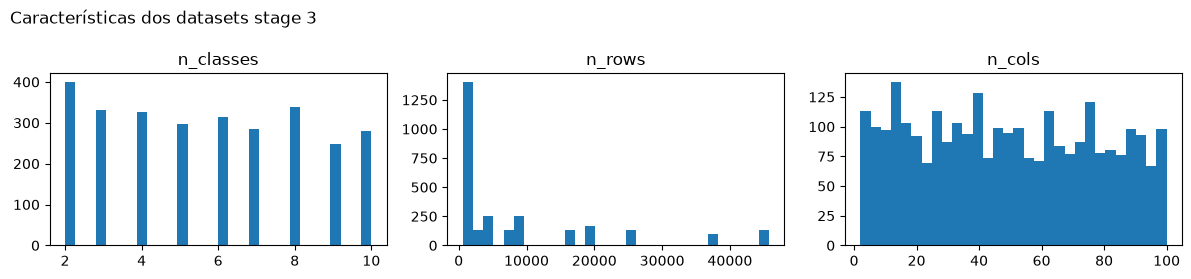

In [11]:
barplot(real, 'Real'); barplot(stage1, 'stage 1'); barplot(stage2, 'stage 2'); barplot(stage3, 'stage 3') 

In [12]:
def boxplot(df, base):
    meta = ["id", "n_classes", "n_rows", "n_cols"]
    medidas = df.drop(columns=meta).dropna(axis="columns", how="all")
    variaveis = medidas.median().sort_values().index.tolist()
    
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * len(variaveis)), 4))
    ax.boxplot([medidas[c].dropna() for c in variaveis])
    ax.set_xticks(
        range(1, len(variaveis) + 1), variaveis,
        rotation=60, ha="right", rotation_mode="anchor",
    )
    ax.set_ylabel("valor da medida")
    ax.set_title(f'Medidas de complexidade da base {base}')
    ax.grid(axis="x", visible=False)
    fig.tight_layout()
    plt.show()

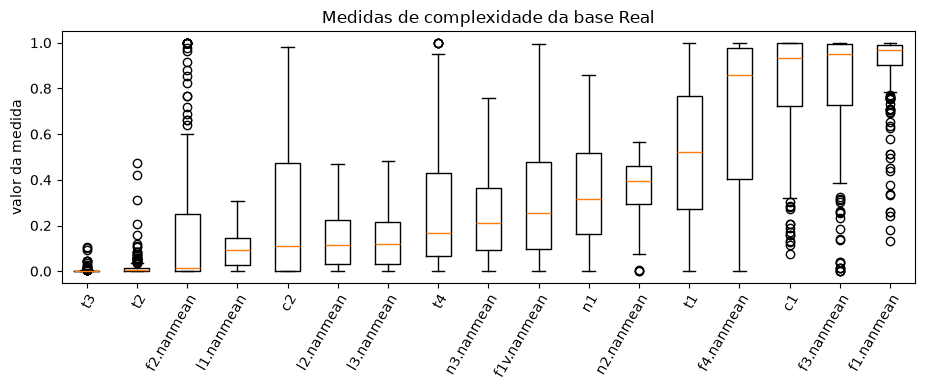

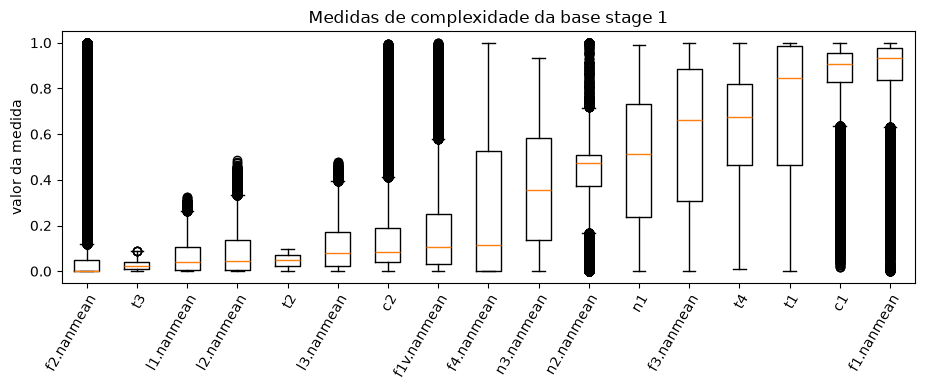

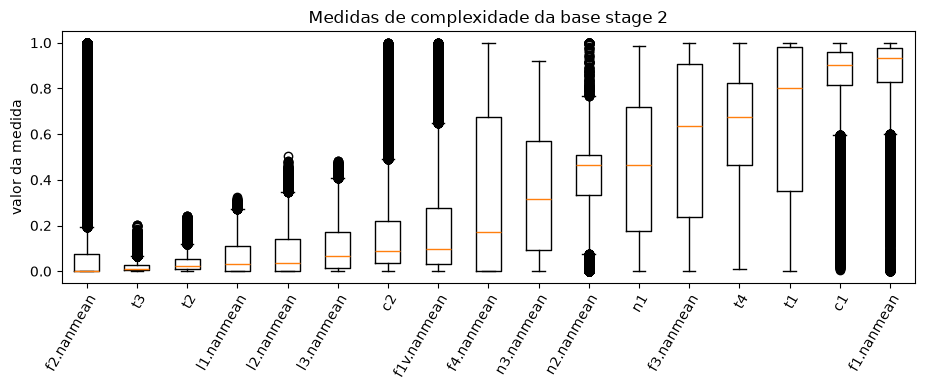

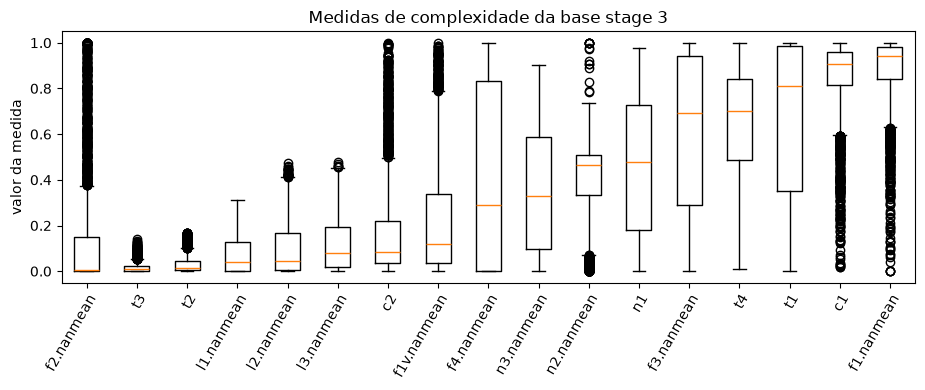

In [13]:
boxplot(real, 'Real'); boxplot(stage1, 'stage 1'); boxplot(stage2, 'stage 2'); boxplot(stage3, 'stage 3') 

In [15]:
def heatmap(df, base):
    cols_corr = df.iloc[:, 4:].dropna(axis="columns", how="all").columns
    corr = df[cols_corr].corr(method="spearman")
    n = len(cols_corr)
    fig, ax = plt.subplots(figsize=(0.45 * n + 2.5, 0.45 * n + 1))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)     # azul = negativa, vermelho = positiva
    ax.set_xticks(range(n), cols_corr, rotation=90)
    ax.set_yticks(range(n), cols_corr)
    ax.grid(False)
    for i in range(n):
        for j in range(n):
            r = corr.iloc[i, j]
            if i != j and abs(r) >= 0.7:                          # anota só as correlações fortes
                ax.text(j, i, f"{r:.1f}", ha="center", va="center", fontsize=6,
                        color="white" if abs(r) > 0.75 else "black")
    fig.colorbar(im, ax=ax, fraction=0.04, label="correlação de Spearman")
    ax.set_title(f'Correlação entre medidas de complexidade da base {base}')
    fig.tight_layout()
    plt.show()

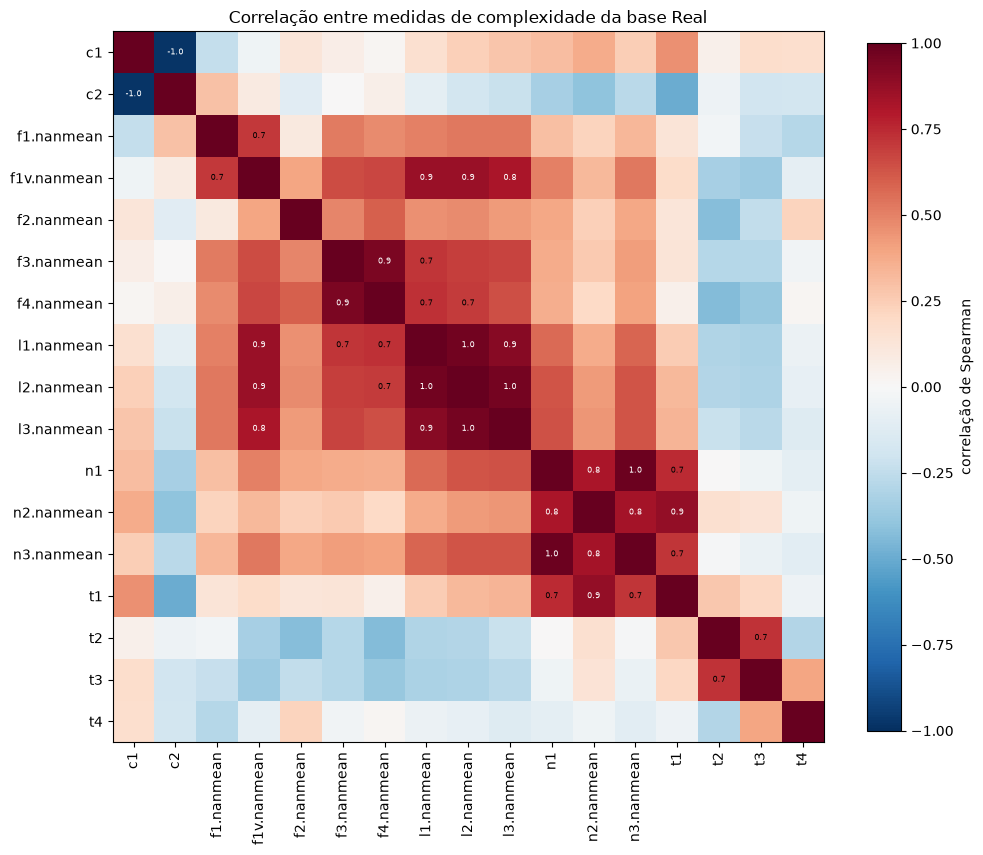

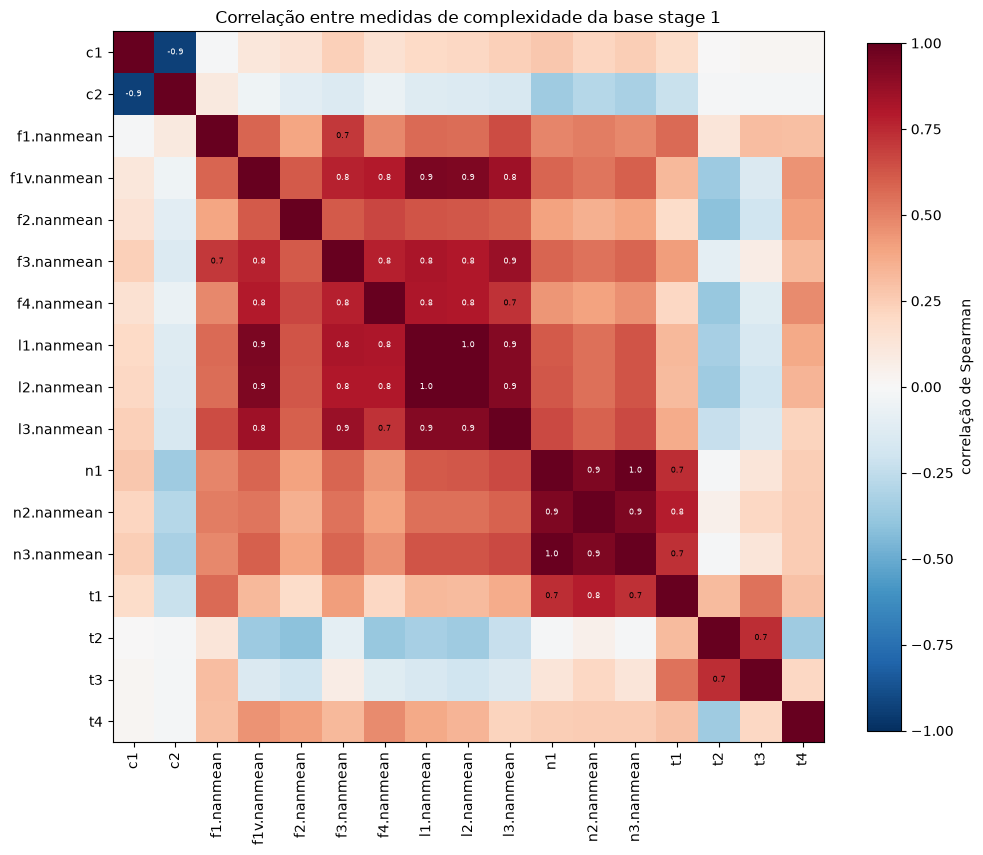

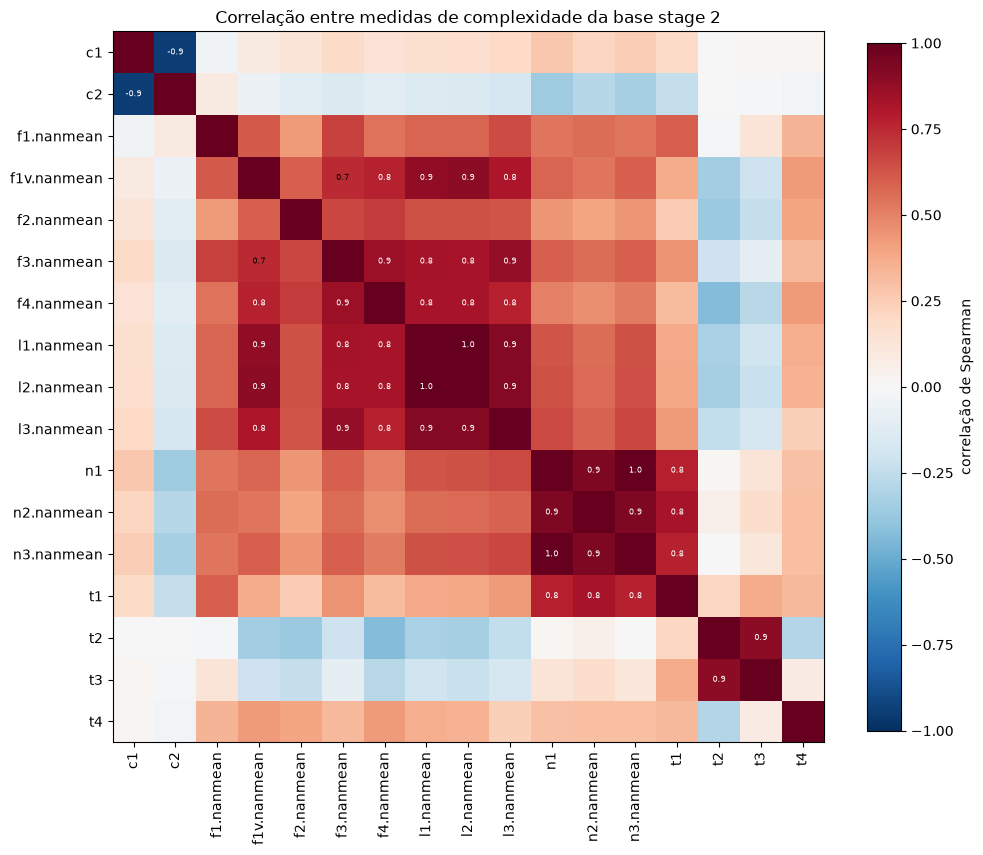

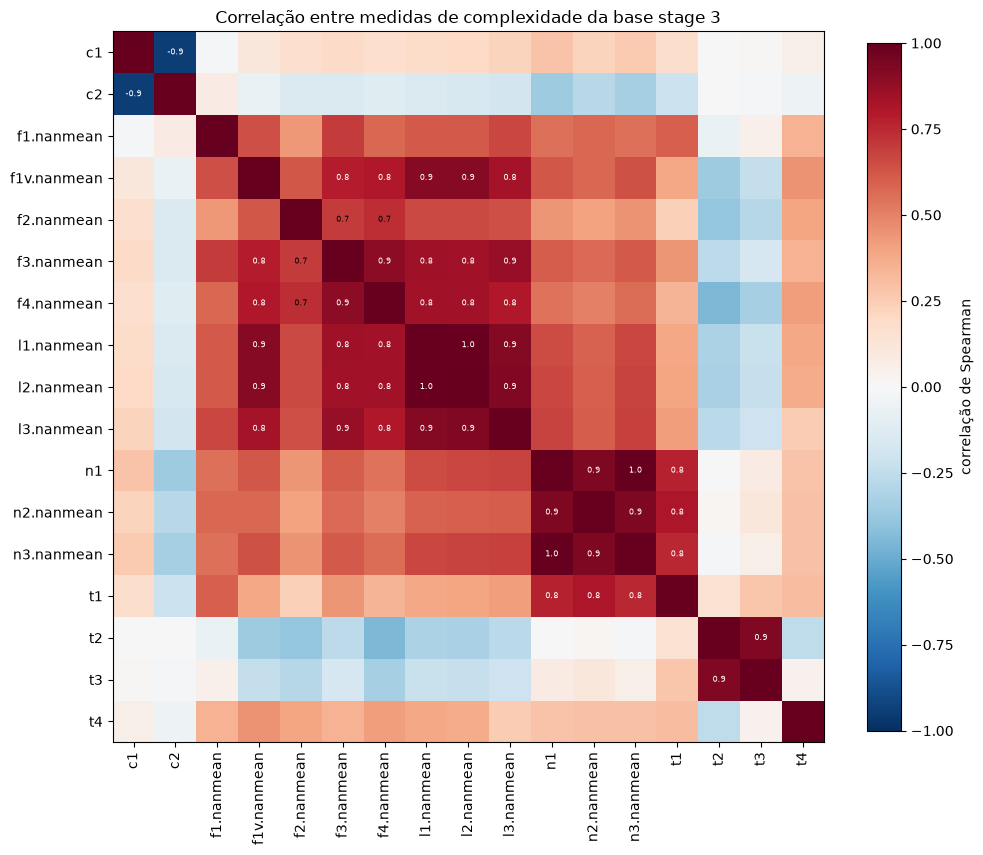

In [16]:
heatmap(real, 'Real'); heatmap(stage1, 'stage 1'); heatmap(stage2, 'stage 2'); heatmap(stage3, 'stage 3') 

In [ ]:
# Próximos passos (antes)
# - usar o prior do tabicl v2
# - definir os hyperparametros de geração das bases
# - rodar as medias de complexidade para bases reais
# - vamos gerar dados sinteticos?

# Próximos passos
# - rodar as medias de complexidade para estágio 3
# - rodar as medias de complexidade para bases reais
# - rodar para 10% dos estágios para as medidas pre-selecionadas 
# - 


# Mais comentarios
# - mais meta-features como impureza de gini (arvore)
# - usar classificadores como metricas
# - 